## Stock Data Download and Stationarity

In [1]:
import yfinance as yf

# Download AAPL stock data
stock_data = yf.download('AAPL', start='2023-01-01')
display(stock_data.head())

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead tr th {
        text-align: left;
    }

    .dataframe thead tr:last-of-type th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr>
      <th>Price</th>
      <th>Close</th>
      <th>High</th>
      <th>Low</th>
      <th>Open</th>
      <th>Volume</th>
    </tr>
    <tr>
      <th>Ticker</th>
      <th>AAPL</th>
      <th>AAPL</th>
      <th>AAPL</th>
      <th>AAPL</th>
      <th>AAPL</th>
    </tr>
    <tr>
      <th>Date</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>2023-01-03</th>
      <td>122.876740</td>
      <td>128.604497</td>
      <td>121.992521</td>
      <td>127.995375</td>
      <td>112117500</td>
    </tr>
    <tr>
      <th>2023-01-04</th>
      <td>124.144127</td>
      <td>126.403797</td>
      <td>122.886574</td>
      <td>124.664832</td>
      <td>89113600</td>
    </tr>
    <tr>
      <th>2023-01-05</th>
      <td>122.827606</td>
      <td>125.529381</td>
      <td>122.572171</td>
      <td>124.900605</td>
      <td>80962700</td>
    </tr>
    <tr>
      <th>2023-01-06</th>
      <td>127.346947</td>
      <td>128.005196</td>
      <td>122.699897</td>
      <td>123.800259</td>
      <td>87754700</td>
    </tr>
    <tr>
      <th>2023-01-09</th>
      <td>127.867645</td>
      <td>131.070487</td>
      <td>127.612210</td>
      <td>128.182041</td>
      <td>70790800</td>
    </tr>
  </tbody>
</table>
</div>

In [2]:
# making data stationary before model fitting
stock_data = yf.download('AAPL', start='2023-01-01')

apple_price_stationary = stock_data['Close'].diff().dropna()

# Split the data into training and testing datasets
train_data, test_data = apple_price_stationary[:-30], apple_price_stationary[-30:]

## AR Model

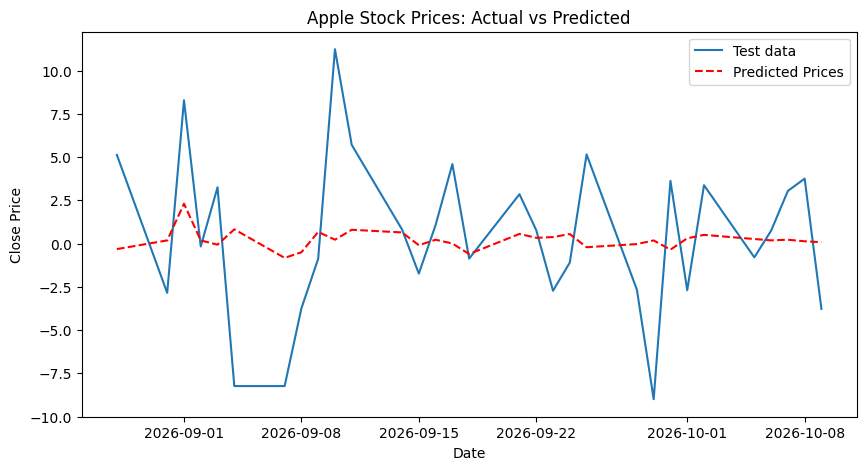

RMSE:  4.45


In [4]:
#| fig-alt: "Chart: Apple Stock Prices: Actual vs Predicted"
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_squared_error
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Ensure the data has an explicit business day frequency to satisfy statsmodels
train_data_clean = train_data.asfreq('B').ffill()
test_data_clean = test_data.asfreq('B').ffill()

# Fit the Autoregressive model (AR) to the training data
model = AutoReg(train_data_clean, lags=30)
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.predict(
    start=len(train_data_clean),
    end=len(train_data_clean) + len(test_data_clean) - 1,
    dynamic=False
)

# Plot the actual vs predicted values
plt.figure(figsize=(10, 5))
plt.plot(test_data_clean.index, test_data_clean, label='Test data')
plt.plot(test_data_clean.index, predictions, color='red', linestyle='--', label='Predicted Prices')
plt.title('Apple Stock Prices: Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()

# evaluating model using RMSE score
rmse = round(np.sqrt(mean_squared_error(test_data_clean, predictions)), 2)
print('RMSE: ', rmse)

## MA Model

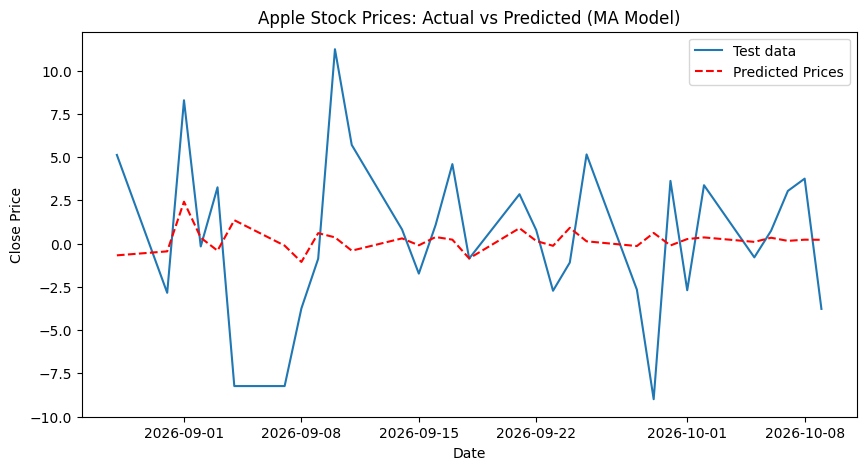

RMSE:  4.55


In [8]:
#| fig-alt: "Chart: Apple Stock Prices: Actual vs Predicted (MA Model)"
from statsmodels.tsa.arima.model import ARIMA

# Fit the Moving Average (MA) model to the training data
# We use train_data_clean and test_data_clean to ensure proper business day frequency alignment
# order=(0, 0, 30) represents order=(p, d, q) where autoregressive order p=0, differencing order d=0, and moving average order q=30
model = ARIMA(train_data_clean, order=(0, 0, 30))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.predict(
    start=len(train_data_clean),
    end=len(train_data_clean) + len(test_data_clean) - 1,
    dynamic=False
)

# Plot the actual vs predicted values
plt.figure(figsize=(10, 5))
plt.plot(test_data_clean.index, test_data_clean, label='Test data')
plt.plot(test_data_clean.index, predictions, color='red', linestyle='--', label='Predicted Prices')
plt.title('Apple Stock Prices: Actual vs Predicted (MA Model)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()

# Evaluating model using RMSE score
rmse = round(np.sqrt(mean_squared_error(test_data_clean, predictions)), 2)
print('RMSE: ', rmse)

## ARMA Model

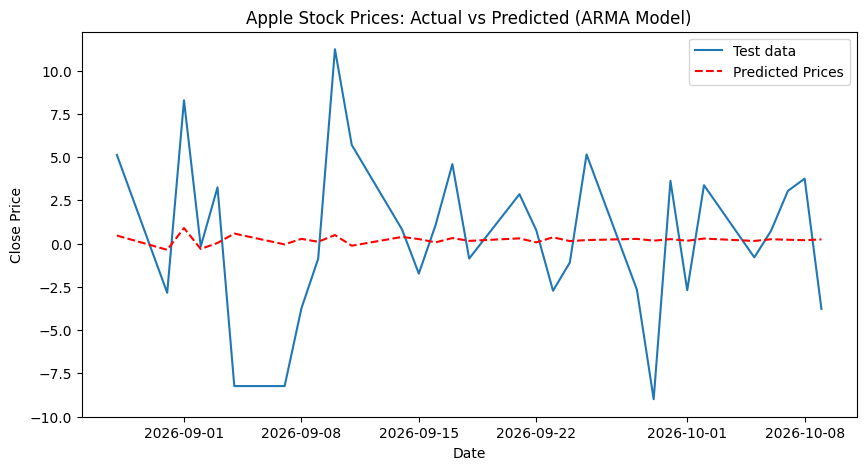

RMSE:  4.51


In [9]:
#| fig-alt: "Chart: Apple Stock Prices: Actual vs Predicted (ARMA Model)"
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Fit the Autoregressive Moving Average (ARMA) model to the training data
# order=(7, 0, 7) corresponds to order=(p, d, q) where:
# p=7 (autoregressive lags), d=0 (no differencing since data is already stationary), and q=7 (moving average lags)
model = ARIMA(train_data_clean, order=(7, 0, 7))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.predict(
    start=len(train_data_clean),
    end=len(train_data_clean) + len(test_data_clean) - 1,
    dynamic=False
)

# Plot the actual vs predicted values
plt.figure(figsize=(10, 5))
plt.plot(test_data_clean.index, test_data_clean, label='Test data')
plt.plot(test_data_clean.index, predictions, color='red', linestyle='--', label='Predicted Prices')
plt.title('Apple Stock Prices: Actual vs Predicted (ARMA Model)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()

# Evaluating model using RMSE score
rmse = round(np.sqrt(mean_squared_error(test_data_clean, predictions)), 2)
print('RMSE: ', rmse)

## ARIMA Model

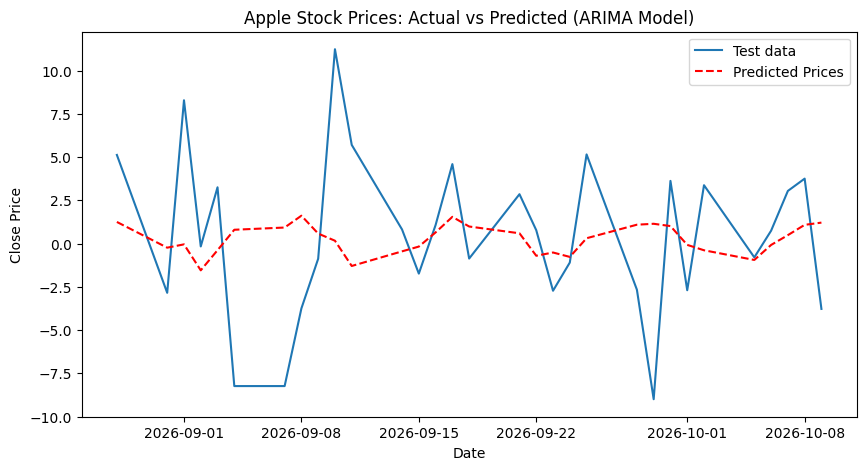

RMSE:  4.79


In [10]:
#| fig-alt: "Chart: Apple Stock Prices: Actual vs Predicted (ARIMA Model)"
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Fit the ARIMA(7,1,7) model to the training data
# order=(7, 1, 7) represents order=(p, d, q) where:
# p=7 (autoregressive lags), d=1 (differencing order), and q=7 (moving average lags)
model = ARIMA(train_data_clean, order=(7, 1, 7))
model_fit = model.fit()

# Make predictions on the test data
predictions = model_fit.predict(
    start=len(train_data_clean),
    end=len(train_data_clean) + len(test_data_clean) - 1,
    dynamic=False
)

# Plot the actual vs predicted values
plt.figure(figsize=(10, 5))
plt.plot(test_data_clean.index, test_data_clean, label='Test data')
plt.plot(test_data_clean.index, predictions, color='red', linestyle='--', label='Predicted Prices')
plt.title('Apple Stock Prices: Actual vs Predicted (ARIMA Model)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()

# Evaluating model using RMSE score
rmse = round(np.sqrt(mean_squared_error(test_data_clean, predictions)), 2)
print('RMSE: ', rmse)

## SARIMA Model

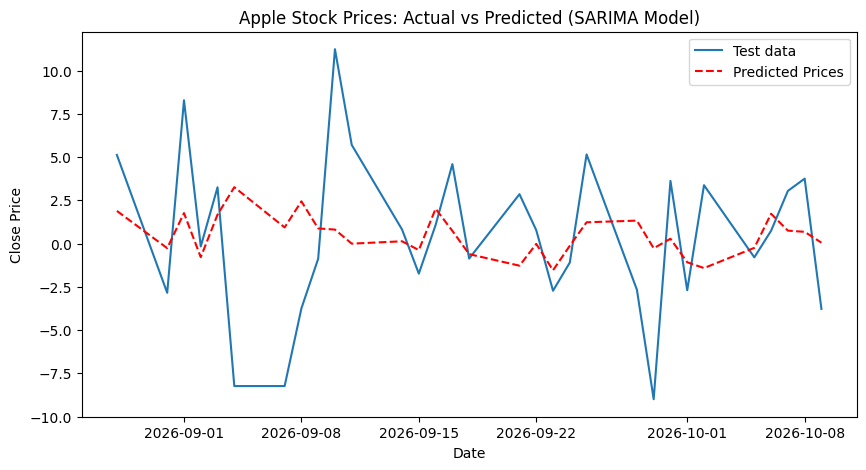

RMSE:  4.66


In [11]:
#| fig-alt: "Chart: Apple Stock Prices: Actual vs Predicted (SARIMA Model)"
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Configure SARIMA parameters
# Non-seasonal parameters: p (AR order), d (differencing), q (MA order)
p, d, q = 7, 1, 7
# Seasonal parameters: P (seasonal AR), D (seasonal differencing), Q (seasonal MA), s (seasonal period)
P, D, Q, s = 1, 1, 1, 45

# Fit the SARIMA model to the clean stationary training data
model = SARIMAX(train_data_clean, order=(p, d, q), seasonal_order=(P, D, Q, s))
model_fit = model.fit(disp=False)

# Make predictions on the test data
predictions = model_fit.predict(
    start=len(train_data_clean),
    end=len(train_data_clean) + len(test_data_clean) - 1,
    dynamic=False
)

# Plot the actual vs predicted values
plt.figure(figsize=(10, 5))
plt.plot(test_data_clean.index, test_data_clean, label='Test data')
plt.plot(test_data_clean.index, predictions, color='red', linestyle='--', label='Predicted Prices')
plt.title('Apple Stock Prices: Actual vs Predicted (SARIMA Model)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.show()

# Evaluating model using RMSE score
rmse = round(np.sqrt(mean_squared_error(test_data_clean, predictions)), 2)
print('RMSE: ', rmse)